# Conditioning on the Base Distribution

In [1]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [ ]:
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 150,
    'font.size': 13,
    'axes.titlesize': 15,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 17,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 2.0,
})

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [ ]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


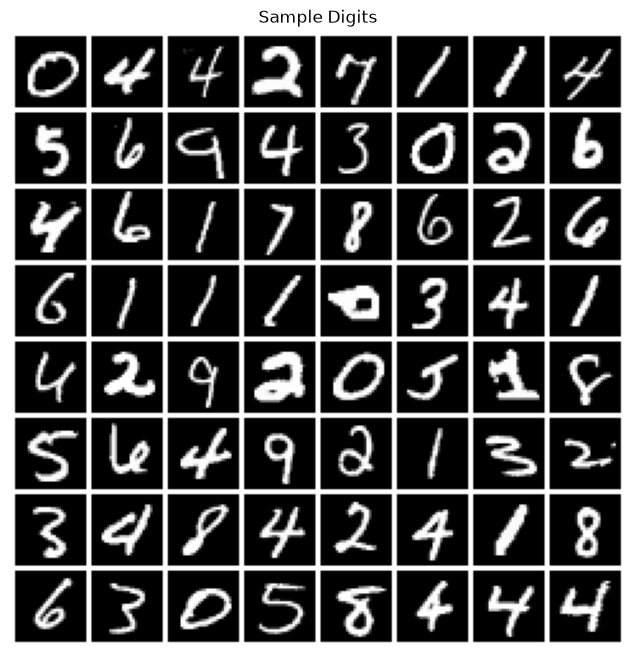

In [4]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

## Condition on base distribution

Class information is injected through the *source distribution* rather than the velocity field. Each class $c$ gets a learned mean $\mu_c \in \mathbb{R}^{784}$, so $x_0 \sim \mathcal{N}(\mu_c, \sigma^2 I)$. At sampling time, drawing $x_0$ from the class-conditional source automatically routes the flow toward the correct digit, with no label input needed by the network.

In [5]:
class CondBaseFlow(nn.Module):
    def __init__(self, dim: int = 784, h: int = 64):
        super().__init__()
        self.mu_emb = nn.Embedding(10, dim)
        # self.log_sigma_emb = nn.Embedding(10, dim)
        self.encoder = nn.Sequential(
            nn.Linear(dim+1, h),
            nn.ReLU(),
            nn.Linear(h, h),
        )
        self.decoder = nn.Sequential(
            nn.Linear(h, h),
            nn.ReLU(),
            nn.Linear(h, dim),
            # nn.Sigmoid()
        )
    
    def forward(self, t: Tensor, x_t: Tensor ) -> Tensor:
        inp = torch.cat((x_t, t), 1)
        z = self.encoder(inp)
        return self.decoder(z)
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t=x_t + self(x_t=x_t, t=t_start)*dt/2, t=t_start + dt/2)

In [6]:
N_EPOCHS = 30
SIGMA_NOISE = 0.1

cond_bflow = CondBaseFlow(h=512).to(device)
opt = torch.optim.Adam(cond_bflow.parameters(), lr=1e-3)
losses = []
preds = []
for e in range(N_EPOCHS):
    tot_loss = 0
    n = 0
    for i, (x, l) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)
        l = l.to(device)

        mu = cond_bflow.mu_emb(l)

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        x_0 = torch.randn_like(x_1)*SIGMA_NOISE + mu
        dx_t = x_1 - x_0
        x_t = (1-t)*x_0 + t * x_1
        flow_pred = cond_bflow(x_t=x_t, t=t)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        tot_loss += loss.item()
        n += 1
        opt.step()
        opt.zero_grad()

    preds.append(flow_pred[0].cpu().detach().numpy())
    losses.append(tot_loss/n)
    print(f'\r[{100*(e+1)/N_EPOCHS:.0f}%] Epoch {e+1}/{N_EPOCHS}  loss: {tot_loss/n:.4f}', end='', flush=True)

[100%] Epoch 30/30  loss: 21.2392

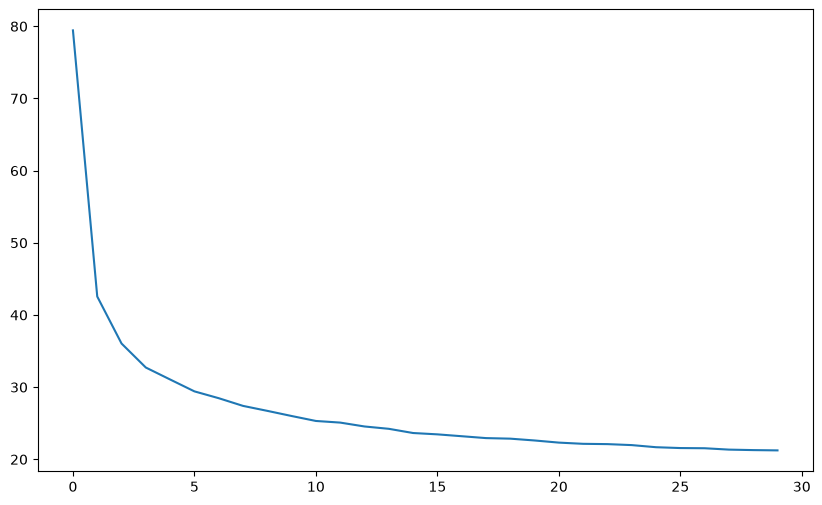

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show();

Text(0.5, 1.0, 't = 1.0')

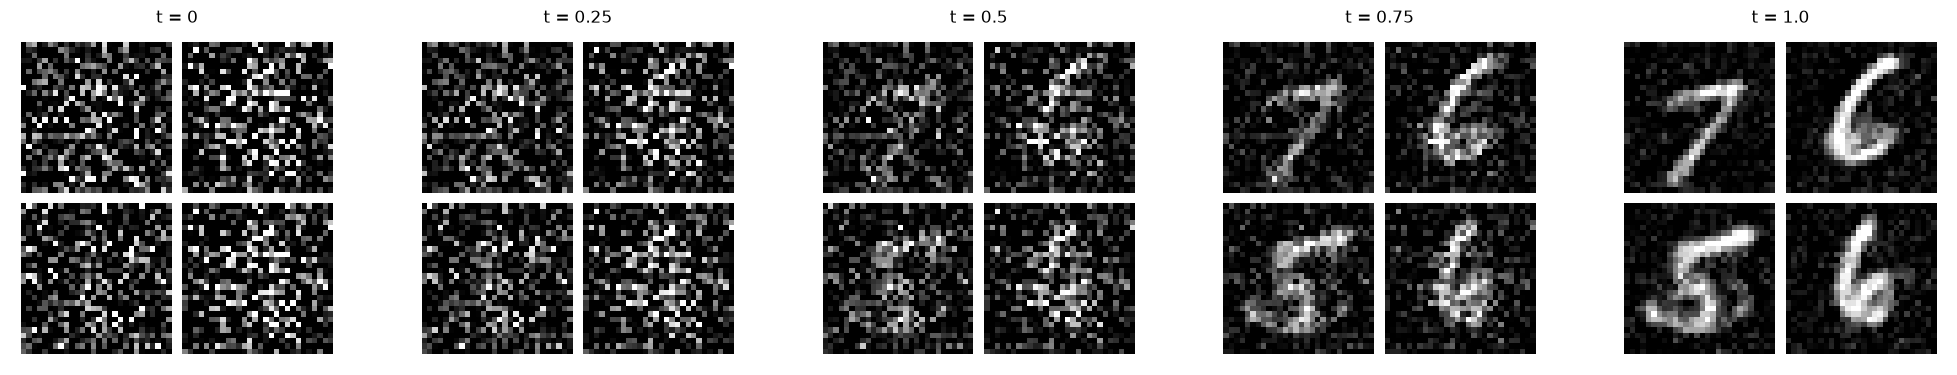

In [8]:
x = torch.randn(6, 784).to(device)
l = torch.randint(10, (6,)).to(device)
mu = cond_bflow.mu_emb(l)
x = x * SIGMA_NOISE + mu
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = cond_bflow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=2, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[int(n_steps*0.25)].view(-1, 1, 28, 28), nrow=2, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[int(n_steps*0.5)].view(-1, 1, 28, 28), nrow=2, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[int(n_steps*0.75)].view(-1, 1, 28, 28), nrow=2, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=2, ax=ax[4])
ax[4].set_title('t = 1.0')

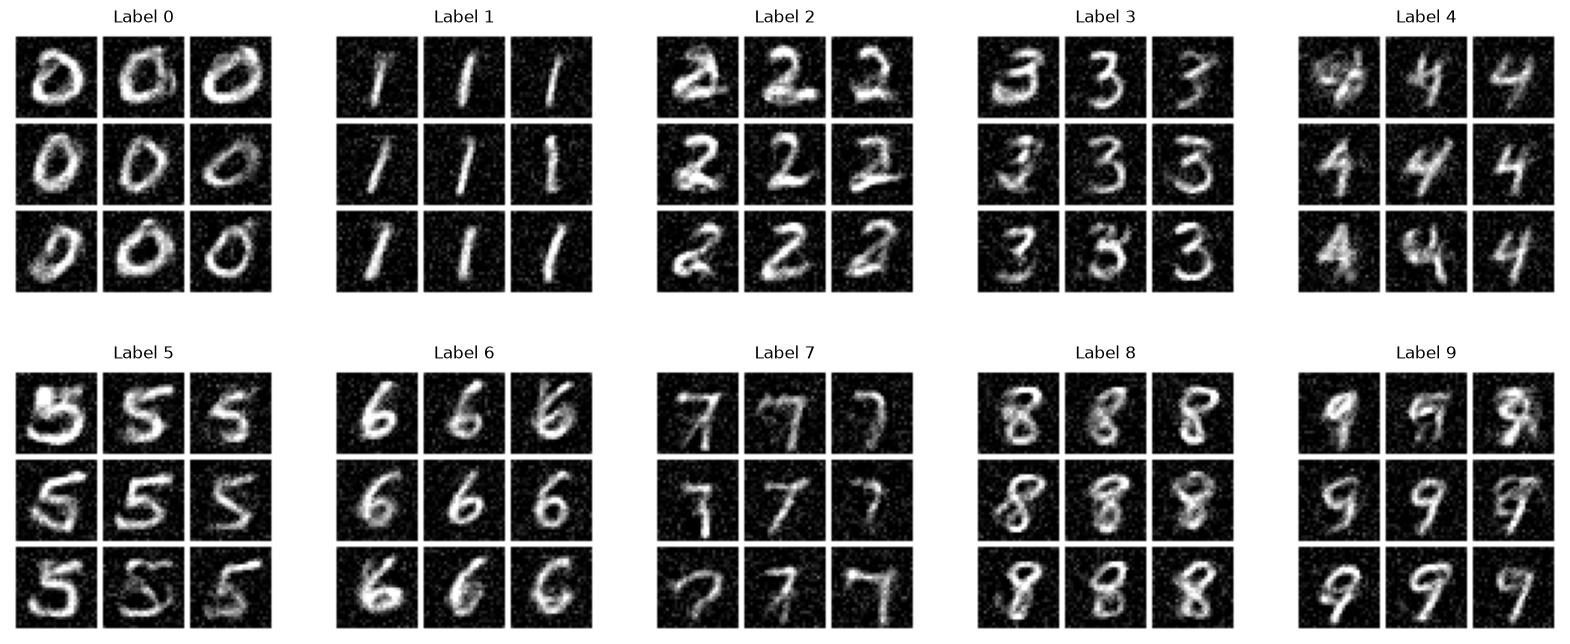

In [9]:
fig, ax = plt.subplots(2, 5, figsize=(20, 8))
ax = ax.reshape(-1)
for l in range(10):
    x = torch.randn(9, 784).to(device)
    mu = cond_bflow.mu_emb(torch.tensor([l]).to(device))
    x = x * SIGMA_NOISE + mu
    n_steps = 100
    time_steps = torch.linspace(0, 1.0, n_steps + 1)

    # Precompute the point cloud at every time step.
    with torch.no_grad():
        for i in range(n_steps):
            x = cond_bflow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))

    ax[l] = show_samples(x.detach().view(-1, 1, 28, 28), nrow=3, ax=ax[l])
    ax[l].set_title(f'Label {l}')
plt.show()

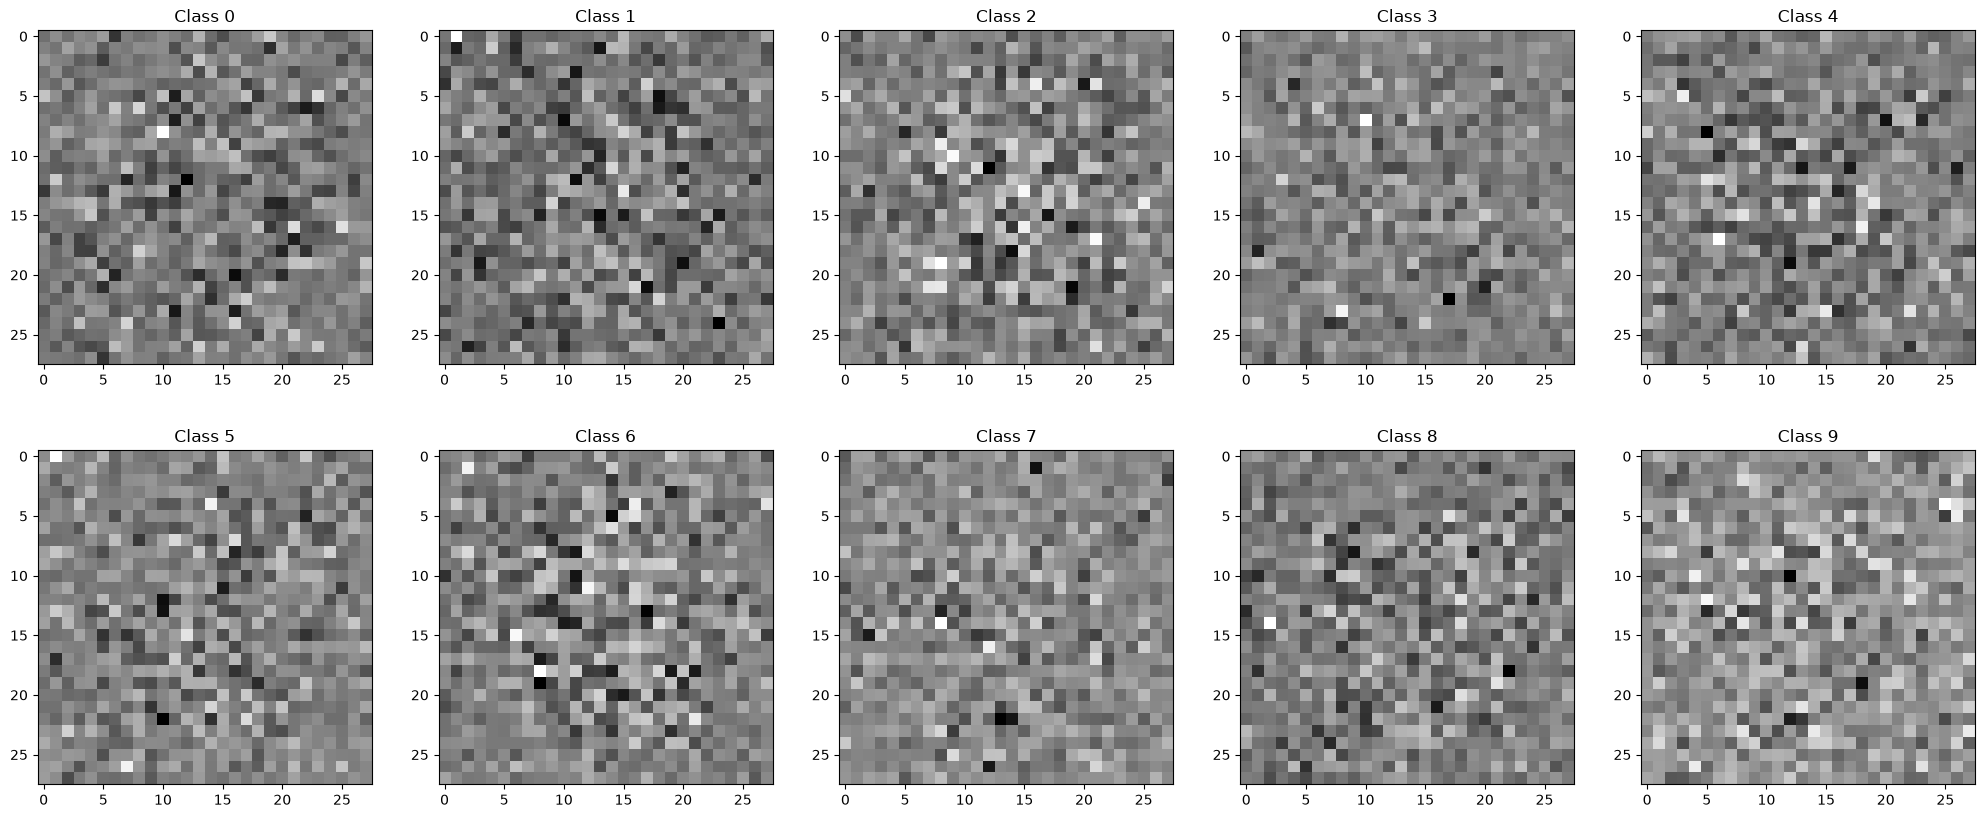

In [11]:
fig, ax = plt.subplots(2, 5, figsize=(25, 10))
ax = ax.reshape(-1)
for i in range(10):
    mu = cond_bflow.mu_emb(torch.tensor(i).to(device)).detach().cpu()
    # mu_scaled = (mu - mu.min()) / (mu.max() - mu.min())
    ax[i].imshow(mu.view(28, 28), cmap='gray')
    ax[i].set_title(f'Class {i}')

plt.show()